# Spatial Regression

Companion to [`notes/spatial_statistics/spatial_regression.md`](../../notes/spatial_statistics/spatial_regression.md).

We simulate point-referenced data with a correct linear mean and spatially correlated errors, then compare OLS and GLS, look at their sampling behavior, diagnose residuals, and compute SAR impacts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

rng = np.random.default_rng(42)
n = 150
coords = rng.uniform(0, 1, size=(n, 2))
x = rng.normal(size=n)
D = cdist(coords, coords)

# Exponential covariance with nugget: Sigma = s2 * exp(-d/a) + nugget * I
s2, a, nug = 1.0, 0.25, 0.2
Sigma = s2 * np.exp(-D / a) + nug * np.eye(n)
L = np.linalg.cholesky(Sigma)

beta_true = np.array([1.0, 2.0])
X = np.column_stack([np.ones(n), x])
eps = L @ rng.normal(size=n)
y = X @ beta_true + eps
print("Corr at d=0.1:", round(float(np.exp(-0.1/a) * s2 / (s2 + nug)), 3))

Corr at d=0.1: 0.559


## OLS versus GLS

OLS: $(X^\top X)^{-1}X^\top y$. GLS: $(X^\top\Sigma^{-1}X)^{-1}X^\top\Sigma^{-1}y$.
The naive OLS covariance is $\hat\sigma^2(X^\top X)^{-1}$; the correct one is the sandwich $(X^\top X)^{-1}X^\top\Sigma X(X^\top X)^{-1}$.
Here $\Sigma$ is treated as known (a teaching device).

In [2]:
XtX_inv = np.linalg.inv(X.T @ X)
b_ols = XtX_inv @ X.T @ y
Si = np.linalg.inv(Sigma)
cov_gls = np.linalg.inv(X.T @ Si @ X)
b_gls = cov_gls @ X.T @ Si @ y

res = y - X @ b_ols
s2_hat = res @ res / (n - 2)
se_naive = np.sqrt(np.diag(s2_hat * XtX_inv))
se_sandwich = np.sqrt(np.diag(XtX_inv @ X.T @ Sigma @ X @ XtX_inv))
se_gls = np.sqrt(np.diag(cov_gls))

print("true      :", beta_true)
print("OLS       :", b_ols.round(3))
print("GLS       :", b_gls.round(3))
print("SE naive OLS    :", se_naive.round(3))
print("SE correct OLS  :", se_sandwich.round(3))
print("SE GLS          :", se_gls.round(3))

true      : [1. 2.]
OLS       : [1.192 2.032]
GLS       : [1.306 1.97 ]
SE naive OLS    : [0.085 0.084]
SE correct OLS  : [0.445 0.075]
SE GLS          : [0.405 0.052]


The naive OLS standard error is generally not the true sampling SD of the OLS estimator; the sandwich value is. Here the intercept's naive SE is far too small (the intercept is most exposed to the shared spatial level of the errors), while the slope's is close because the predictor itself is not spatially structured. With a spatially smooth predictor the slope SE would also be understated. GLS has the smallest variance of the linear unbiased estimators under the correct $\Sigma$. A repeated-sampling check follows.

slope mean  OLS 1.998  GLS 1.999 (true 2)
slope SD    OLS 0.076  GLS 0.052
theory SD   OLS 0.075  GLS 0.052


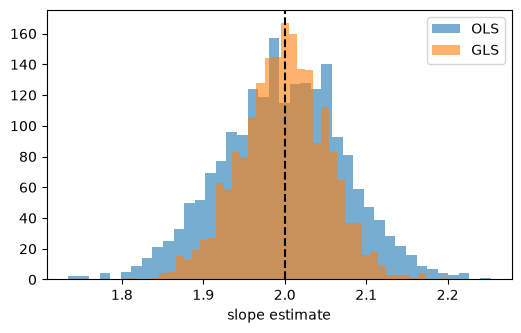

In [3]:
R = 2000
ols_s, gls_s = np.empty(R), np.empty(R)
A_gls = cov_gls @ X.T @ Si
A_ols = XtX_inv @ X.T
for r in range(R):
    yy = X @ beta_true + L @ rng.normal(size=n)
    ols_s[r] = (A_ols @ yy)[1]
    gls_s[r] = (A_gls @ yy)[1]
print("slope mean  OLS %.3f  GLS %.3f (true 2)" % (ols_s.mean(), gls_s.mean()))
print("slope SD    OLS %.3f  GLS %.3f" % (ols_s.std(), gls_s.std()))
print("theory SD   OLS %.3f  GLS %.3f" % (se_sandwich[1], se_gls[1]))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(ols_s, bins=40, alpha=.6, label="OLS")
ax.hist(gls_s, bins=40, alpha=.6, label="GLS")
ax.axvline(2, color="k", ls="--"); ax.set_xlabel("slope estimate"); ax.legend()
plt.show()

## Whitened residuals

GLS residuals $e=y-X\hat\beta_{GLS}$ are still correlated by design. Whitening, $e^*=L^{-1}e$, should remove that structure if the covariance model is adequate. We compare a simple distance-bin correlation of raw versus whitened residuals.

In [4]:
from scipy.linalg import solve_triangular
e = y - X @ b_gls
e_star = solve_triangular(L, e, lower=True)

iu = np.triu_indices(n, 1)
d = D[iu]
bins = [0, .1, .2, .4, .8]
def binned_corr(v):
    prod = np.outer(v, v)[iu] / v.var()
    return [prod[(d >= lo) & (d < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]
print("distance bin      raw   whitened")
for lo, hi, r, w in zip(bins[:-1], bins[1:], binned_corr(e), binned_corr(e_star)):
    print(f"[{lo:.1f},{hi:.1f})      {r:6.3f}  {w:6.3f}")

distance bin      raw   whitened


[0.0,0.1)       0.603  -0.025
[0.1,0.2)       0.435   0.033
[0.2,0.4)       0.147  -0.001
[0.4,0.8)      -0.139  -0.012


## Spatial lag (SAR) impacts

For $y=\rho Wy+X\beta+\varepsilon$, $\partial E[y]/\partial x^\top=(I-\rho W)^{-1}\beta$. We reproduce the chain $A-B-C$ example from the notes with $\rho=0.4$, $\beta=2$.

In [5]:
W = np.array([[0, 1, 0], [.5, 0, .5], [0, 1, 0]])
rho, b = 0.4, 2.0
S = np.linalg.inv(np.eye(3) - rho * W)
impact = b * S
print(np.round(impact, 3))
print("direct (diagonal mean):  %.3f" % np.mean(np.diag(impact)))
print("indirect (mean of off-diagonal row sums): %.3f" % np.mean(impact.sum(1) - np.diag(impact)))
print("spatial error shock u=(I-0.4W)^-1 [1,0,0]:", np.round(S @ np.array([1, 0, 0]), 3))
print("max |eigenvalue| of W (<=1 for row-standardized):", np.abs(np.linalg.eigvals(W)).max().round(3))

[[2.19  0.952 0.19 ]
 [0.476 2.381 0.476]
 [0.19  0.952 2.19 ]]
direct (diagonal mean):  2.254
indirect (mean of off-diagonal row sums): 1.079
spatial error shock u=(I-0.4W)^-1 [1,0,0]: [1.095 0.238 0.095]
max |eigenvalue| of W (<=1 for row-standardized): 1.0


## Takeaways

- The mean model was correct, so OLS is unbiased; the issue is incorrect naive uncertainty and lost efficiency.
- GLS with the right covariance is more precise; in practice $\Sigma$ must be estimated (feasible GLS).
- SAR coefficients are not total effects: impacts propagate through $(I-\rho W)^{-1}$.